In [2]:
import pandas as pd
import numpy as np
import duckdb
import os
import requests
from dotenv import load_dotenv
from datetime import datetime


import seaborn as sns
import matplotlib.pyplot as plt

from alpaca.data.historical import CryptoHistoricalDataClient, StockHistoricalDataClient
from alpaca.data.requests import CryptoBarsRequest, StockBarsRequest

from alpaca.data.timeframe import TimeFrame

In [3]:
#Cargamos entorno
load_dotenv()

API_KEY= os.getenv('API_KEY')
SECRET_KEY= os.getenv('SECRET_KEY')
ENDPOINT= os.getenv('ENDPOINT')

print(ENDPOINT)

https://paper-api.alpaca.markets/v2


In [4]:
client = CryptoHistoricalDataClient()

request_params = CryptoBarsRequest(
    symbol_or_symbols=['BTC/USD'],
    timeframe=TimeFrame.Day,
    start= datetime(2026, 1, 1),
    end= datetime(2026, 9, 30)
)

btc_bars = client.get_crypto_bars(request_params).df


btc_bars.round(2)

open      high       low     close  \
symbol  timestamp                                                           
BTC/USD 2026-01-01 00:00:00+00:00  87513.64  88814.01  87351.40  88756.75   
        2026-01-02 00:00:00+00:00  88734.76  90937.27  87463.93  89962.89   
        2026-01-03 00:00:00+00:00  89959.70  90712.96  89268.39  90596.72   
        2026-01-04 00:00:00+00:00  90628.95  91770.99  90519.09  91499.40   
        2026-01-05 00:00:00+00:00  91497.71  94819.49  91012.98  93884.59   
...                                     ...       ...       ...       ...   
        2026-09-26 00:00:00+00:00  84088.67  84446.38  83777.98  84411.42   
        2026-09-27 00:00:00+00:00  84399.05  85141.42  84113.97  84457.95   
        2026-09-28 00:00:00+00:00  84457.96  84986.93  82547.94  83454.24   
        2026-09-29 00:00:00+00:00  83465.00  84530.68  82739.96  83630.32   
        2026-09-30 00:00:00+00:00  83631.01  85609.33  82916.25  83562.55   

                                   volume  trade_count      vwap  
symbol  timestamp                                                 
BTC/USD 2026-01-01 00:00:00+00:00    1.00        300.0  87837.00  
        2026-01-02 00:00:00+00:00    1.18        518.0  89422.77  
        2026-01-03 00:00:00+00:00    0.76        417.0  90012.49  
        2026-01-04 00:00:00+00:00    0.60        439.0  91199.27  
        2026-01-05 00:00:00+00:00    3.55        626.0  93309.72  
...                                   ...          ...       ...  
        2026-09-26 00:00:00+00:00    0.48        533.0  84077.19  
        2026-09-27 00:00:00+00:00    0.47        679.0  84684.68  
        2026-09-28 00:00:00+00:00    1.51        957.0  83520.99  
        2026-09-29 00:00:00+00:00    0.70        744.0  83603.35  
        2026-09-30 00:00:00+00:00    1.18        952.0  84140.24  

[273 rows x 7 columns]

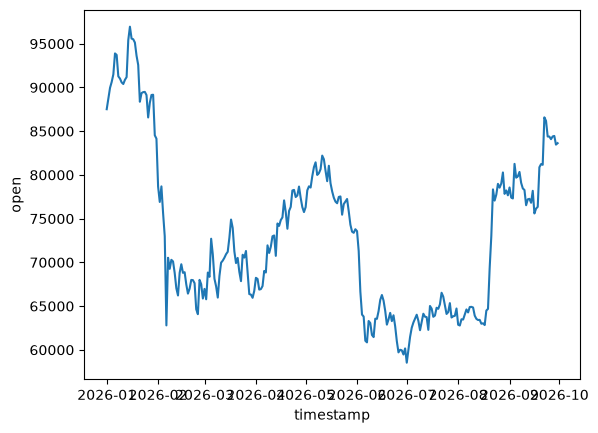

In [5]:
plt.tight_layout()
sns.lineplot(btc_bars, x= 'timestamp', y='open',)


plt.show()

In [6]:
client = StockHistoricalDataClient(api_key=API_KEY, secret_key=SECRET_KEY)

symbols = ['BOY','SCPX']

request_params = StockBarsRequest(
    symbol_or_symbols=symbols,
    timeframe=TimeFrame.Day,
    start= datetime(2026, 1, 1),
    end= datetime(2026, 9, 30)
)

stocks = client.get_stock_bars(request_params).df




In [9]:
import yfinance as yf

# Índice IBEX 35 y algunos valores representativos
tickers = ["^IBEX", "SAN.MC", "ITX.MC", "BBVA.MC", "REP.MC"]

datos = yf.download(tickers, start="2024-01-01", end="2024-12-31")
df_close = datos["Close"]
df_close

[*********************100%***********************]  5 of 5 completed


Ticker,BBVA.MC,ITX.MC,REP.MC,SAN.MC,^IBEX
Date,,,,,
2024-01-02,7.209343,36.022579,11.101337,3.542465,10182.099609
2024-01-03,7.118648,34.918442,11.105433,3.492824,10053.400391
2024-01-04,7.238434,34.973648,11.232372,3.566826,10182.400391
2024-01-05,7.284636,34.614803,11.269226,3.596703,10164.500000
2024-01-08,7.359930,35.028854,11.105433,3.612331,10209.000000
...,...,...,...,...,...
2024-12-20,8.506859,47.538471,9.617619,4.177856,11467.299805
2024-12-23,8.505031,46.949699,9.704932,4.153881,11435.700195
2024-12-24,8.473937,47.016171,9.774783,4.143812,11473.900391
